In [17]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import seaborn as sns

In [52]:
file = Path.cwd().parent / "mlruns" / "curve" / "tune_top_k" / "2d566a4004e848638d4e4a4c52ca0cdb" / "top_k_curve.csv"
df = pd.read_csv(file)
df

,top_k,hit_rate,recall,precision,mrr,ndcg,chunk_precision,scored_entries,coverage
0,1,0.825397,0.662698,0.825397,0.825397,0.825397,0.825397,63,1.0
1,2,0.904762,0.812169,0.650794,0.865079,0.859315,0.650794,63,1.0
2,3,0.968254,0.907407,0.539683,0.886243,0.886717,0.555556,63,1.0
3,4,0.968254,0.927249,0.456349,0.886243,0.886717,0.488095,63,1.0
4,5,0.968254,0.931217,0.398413,0.886243,0.886717,0.438095,63,1.0
5,6,0.984127,0.962963,0.379101,0.889418,0.902590,0.412698,63,1.0
6,7,0.984127,0.978836,0.337831,0.889418,0.907198,0.387755,63,1.0
7,8,0.984127,0.978836,0.311073,0.889418,0.907198,0.367063,63,1.0
8,9,0.984127,0.984127,0.291660,0.889418,0.910407,0.349206,63,1.0
9,10,0.984127,0.984127,0.277708,0.889418,0.910407,0.331746,63,1.0


In [53]:
betas = range(1, 21)
for beta in betas:
    df[f'f_{beta}_score'] = (1 + beta**2) * (df['precision'] * df['recall']) / ((beta**2 * df['precision']) + df['recall'])
df

,top_k,hit_rate,recall,precision,mrr,ndcg,chunk_precision,scored_entries,coverage,f_1_score,...,f_11_score,f_12_score,f_13_score,f_14_score,f_15_score,f_16_score,f_17_score,f_18_score,f_19_score,f_20_score
0,1,0.825397,0.662698,0.825397,0.825397,0.825397,0.825397,63,1.0,0.735153,...,0.663770,0.663600,0.663467,0.663362,0.663277,0.663207,0.663149,0.663100,0.663059,0.663024
1,2,0.904762,0.812169,0.650794,0.865079,0.859315,0.650794,63,1.0,0.722581,...,0.810522,0.810782,0.810986,0.811148,0.811279,0.811386,0.811475,0.811550,0.811613,0.811667
2,3,0.968254,0.907407,0.539683,0.886243,0.886717,0.555556,63,1.0,0.676823,...,0.902367,0.903163,0.903785,0.904279,0.904679,0.905008,0.905280,0.905509,0.905702,0.905868
3,4,0.968254,0.927249,0.456349,0.886243,0.886717,0.488095,63,1.0,0.611665,...,0.919472,0.920697,0.921655,0.922417,0.923035,0.923541,0.923961,0.924314,0.924613,0.924869
4,5,0.968254,0.931217,0.398413,0.886243,0.886717,0.438095,63,1.0,0.558063,...,0.921120,0.922707,0.923949,0.924938,0.925739,0.926396,0.926942,0.927401,0.927790,0.928122
5,6,0.984127,0.962963,0.379101,0.889418,0.902590,0.412698,63,1.0,0.544028,...,0.950958,0.952842,0.954317,0.955493,0.956445,0.957227,0.957876,0.958421,0.958883,0.959279
6,7,0.984127,0.978836,0.337831,0.889418,0.907198,0.387755,63,1.0,0.502300,...,0.963846,0.966193,0.968032,0.969498,0.970686,0.971662,0.972473,0.973155,0.973732,0.974226
7,8,0.984127,0.978836,0.311073,0.889418,0.907198,0.367063,63,1.0,0.472110,...,0.961911,0.964556,0.966630,0.968285,0.969626,0.970728,0.971644,0.972413,0.973066,0.973624
8,9,0.984127,0.984127,0.291660,0.889418,0.910407,0.349206,63,1.0,0.449966,...,0.965341,0.968273,0.970572,0.972408,0.973896,0.975119,0.976135,0.976990,0.977715,0.978335
9,10,0.984127,0.984127,0.277708,0.889418,0.910407,0.331746,63,1.0,0.433179,...,0.964027,0.967160,0.969618,0.971582,0.973173,0.974482,0.975570,0.976484,0.977260,0.977924


(0.8, 1.0)

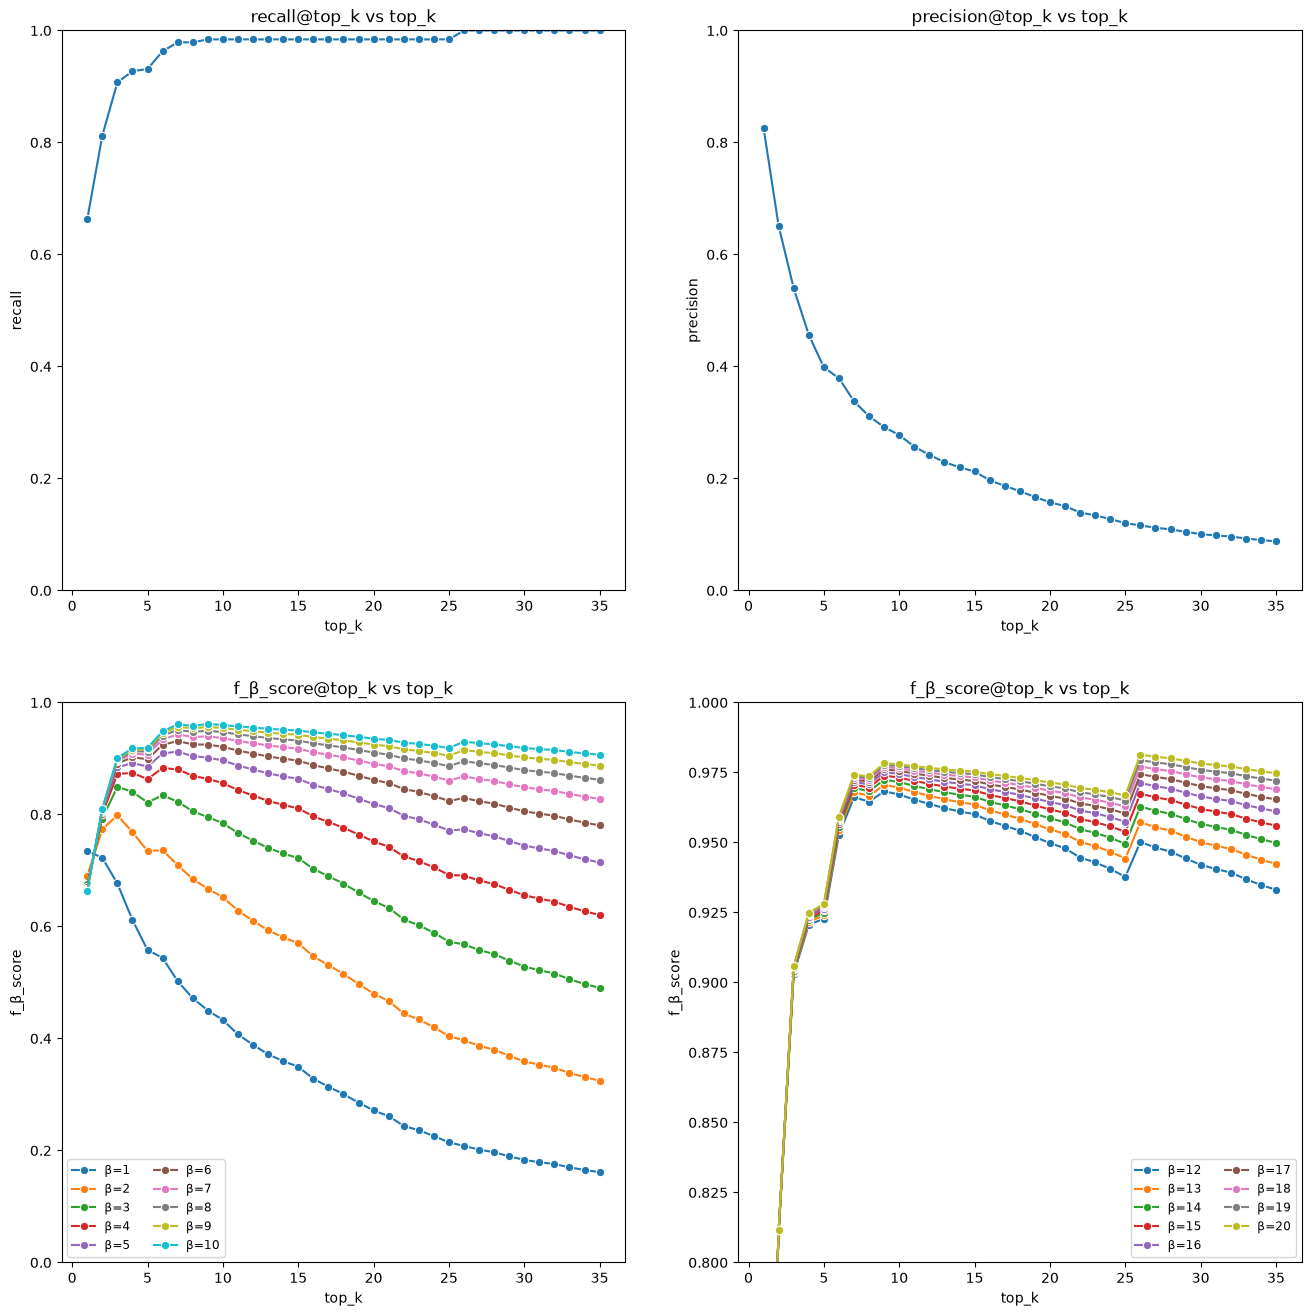

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

axis = axes[0, 0]
sns.lineplot(data=df, x='top_k', y='recall', marker='o', ax=axis)
axis.set(xlabel='top_k', ylabel='recall', title="recall@top_k vs top_k")
axis.set_ylim(0, 1)

axis = axes[0, 1]
sns.lineplot(data=df, x='top_k', y='precision', marker='o', ax=axis)
axis.set(xlabel='top_k', ylabel='precision', title="precision@top_k vs top_k")
axis.set_ylim(0, 1)

axis = axes[1, 0]
for beta in betas[:10]:
    sns.lineplot(data=df, x='top_k', y=f'f_{beta}_score', marker='o', label=f'β={beta}', ax=axis)
axis.legend(ncol=2, fontsize='small')
axis.set(xlabel='top_k', ylabel=f'f_β_score', title=f"f_β_score@top_k vs top_k")
axis.set_ylim(0, 1)

axis = axes[1, 1]
for beta in betas[11:]:
    sns.lineplot(data=df, x='top_k', y=f'f_{beta}_score', marker='o', label=f'β={beta}', ax=axis)
axis.legend(ncol=2, fontsize='small')
axis.set(xlabel='top_k', ylabel=f'f_β_score', title=f"f_β_score@top_k vs top_k")
# axis.set_yscale('log')
axis.set_ylim(0.8, 1)

In [58]:
# print(df)

What is the aim:
- find a metric that combines recall and precision, with a heavy weight on the recall performance. So to say a metric which can suggest: recall is good enough, a small decreease of recall is acceptable if it is correlated with an increase of precision.
- the problem with using recall alone:
    - recall is saturated (value > 0.97) when top_k >= 7. A value of top_k around 7-9 can be understood as there are questions with up to 4 relevant documents in the golden set so it leaves some room for inefficiencies.
    - recall reaches 1.0 (maximum) when top_k >= 26. In this case the improvement of recall is minimal with the penalty of a much bigger and noisy context.

F-scores might be good candidates. Here are shown the behaviours of the f-beta metrics for various betta values. What is observed:
- beta 1-4 -> peak is at top_k <= 6 (too small)
- beta 5-9 -> peak is at top_k = 7 (ok)
- beta 10-17 -> peak is at top_k = 9 (ok)
- beta 18-20 -> peak is at top_k = 26 (too high)

So suitable choices of betta are between 5 and 17. A higher value corresponds to a larger weight set on recall and lower weight set on precision. The behaviour of the f-score seems similar within this betta range. In order to avoid possible jumps in behaviour, a value around the middle of the interval is picked:
**beta=10**.